Projeto 01 - Análise Exploratória de Dados Olist
Objetivo
Analisar os dados de pedidos do marketplace Olist para entender padrões de vendas, qualidade dos dados e oportunidades de negócio.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [ ]:
os.listdir("../data")

Carregamento dos dados
Nesta etapa carregamos a base de pedidos do dataset Olist para entender a estrutura das informações.

In [ ]:

orders = pd.read_csv("../data/olist_orders_dataset.csv")

Primeiras Linhas

In [ ]:
orders.head()

In [8]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [9]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

## Análise de Valores Nulos

A base apresenta dados faltantes principalmente relacionados ao fluxo de entrega.

Os maiores volumes de valores nulos estão nas colunas:

- order_delivered_customer_date
- order_delivered_carrier_date

Isso pode indicar pedidos cancelados, pedidos em andamento ou registros de entrega não concluídos.

As colunas fundamentais para identificação dos pedidos e clientes não apresentam valores ausentes.

--------------------------------------------------------------------------

Esse é um dos gráficos mais importantes do dataset Olist.

Ele vai responder:

Quantos pedidos foram entregues?
Quantos foram cancelados?
Quantos estão em transporte?
Quantos estão processando?

In [10]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

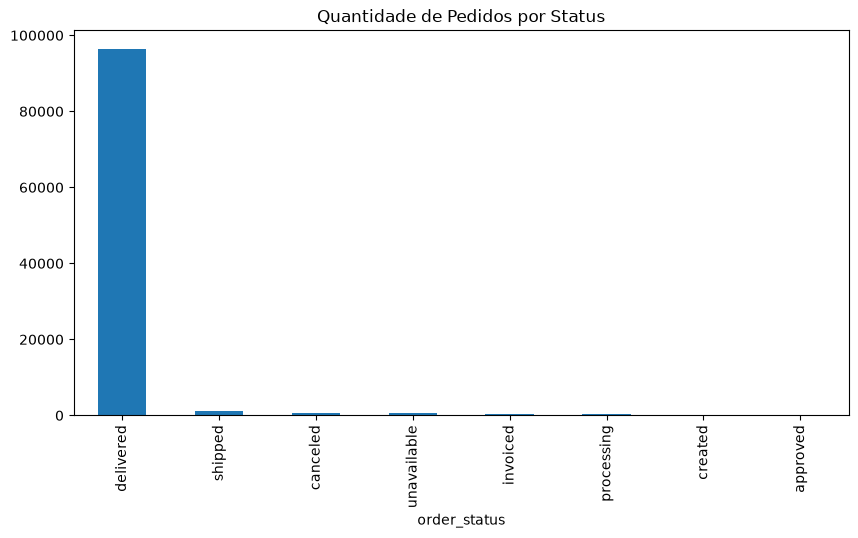

In [11]:
orders["order_status"].value_counts().plot(
    kind="bar",
    figsize=(10,5)
)
plt.title("Quantidade de Pedidos por Status")
plt.show()

## Análise dos Tempos de Entrega

Nesta etapa vamos calcular o tempo entre a compra e a entrega do pedido, permitindo entender a eficiência logística da operação.

In [14]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [15]:
orders["delivery_time_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.days


In [16]:
orders[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "delivery_time_days"
    ]
].head()

,order_purchase_timestamp,order_delivered_customer_date,delivery_time_days
0,2017-10-02 10:56:33,2017-10-10 21:25:13,8.0
1,2018-07-24 20:41:37,2018-08-07 15:27:45,13.0
2,2018-08-08 08:38:49,2018-08-17 18:06:29,9.0
3,2017-11-18 19:28:06,2017-12-02 00:28:42,13.0
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2.0


In [17]:
orders["delivery_time_days"].describe()

count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_time_days, dtype: float64

Esse gráfico já começa a responder:

Qual o prazo típico de entrega?
Existem entregas muito demoradas?
Existem outliers?

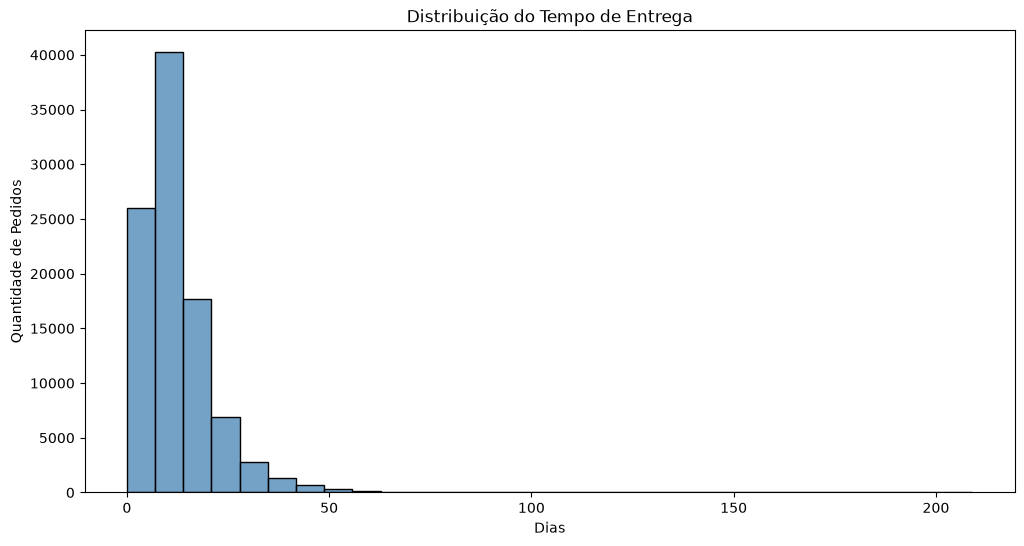

In [18]:
plt.figure(figsize=(12,6))

sns.histplot(
    orders["delivery_time_days"],
    bins=30,
    color="steelblue"
)

plt.title("Distribuição do Tempo de Entrega")
plt.xlabel("Dias")
plt.ylabel("Quantidade de Pedidos")

plt.show()

## Insight Inicial

A distribuição dos tempos de entrega permite identificar o comportamento padrão da operação logística.

Pedidos com prazo muito superior à média podem indicar gargalos operacionais, problemas de transporte ou restrições geográficas.

In [36]:
media_entrega = int(orders["delivery_time_days"].mean())
mediana_entrega = int(orders["delivery_time_days"].median())
maior_entrega = int(orders["delivery_time_days"].max())
menor_entrega = int(orders["delivery_time_days"].min())

print(f"📦 Tempo médio de entrega: {media_entrega} dias")
print(f"📊 Mediana do tempo de entrega: {mediana_entrega} dias")
print(f"🚚 Maior tempo de entrega: {maior_entrega} dias")

if menor_entrega == 0:
    print("⚡ Menor prazo de entrega: no mesmo dia da compra")
else:
    print(f"⚡ Menor prazo de entrega: {menor_entrega} dias")

📦 Tempo médio de entrega: 12 dias
📊 Mediana do tempo de entrega: 10 dias
🚚 Maior tempo de entrega: 209 dias
⚡ Menor prazo de entrega: no mesmo dia da compra


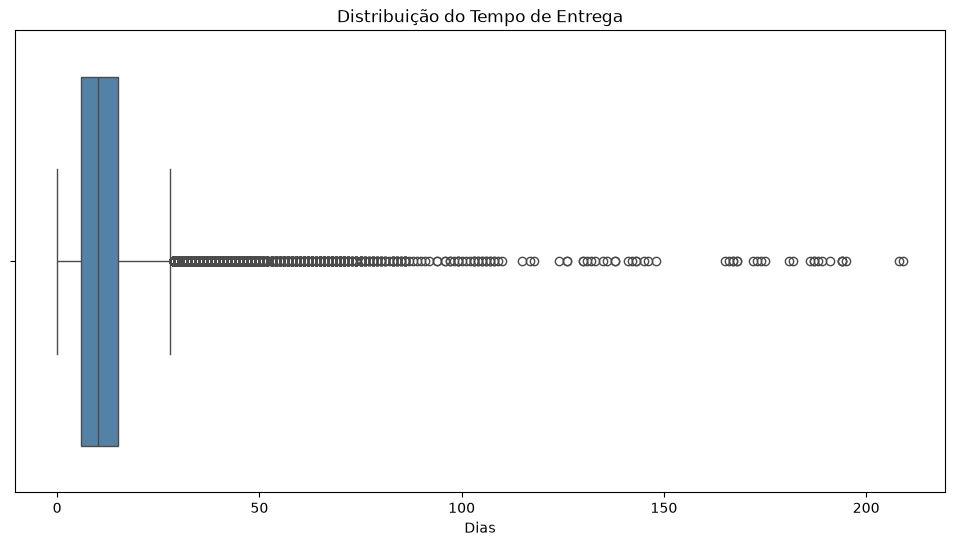

In [23]:
plt.figure(figsize=(12,6))

sns.boxplot(
    x=orders["delivery_time_days"],
    color="steelblue"
)

plt.title("Distribuição do Tempo de Entrega")
plt.xlabel("Dias")

plt.show()

In [25]:
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.days

In [37]:
orders["delivery_delay_days"]

0        -8.0
1        -6.0
2       -18.0
3       -13.0
4       -10.0
         ... 
99436   -11.0
99437    -2.0
99438    -6.0
99439   -21.0
99440   -18.0
Name: delivery_delay_days, Length: 99441, dtype: float64

In [40]:

atrasados = (orders["delivery_delay_days"] > 0).sum()

no_prazo = (orders["delivery_delay_days"] <= 0).sum()

taxa_atraso = (
    (orders["delivery_delay_days"] > 0).mean() * 100
)

print(f"🚨 Pedidos atrasados: {atrasados}")
print(f"✅ Pedidos no prazo: {no_prazo}")
print(f"📦 Taxa de pedidos atrasados: {taxa_atraso:.1f}%")

🚨 Pedidos atrasados: 6535
✅ Pedidos no prazo: 89941
📦 Taxa de pedidos atrasados: 6.6%


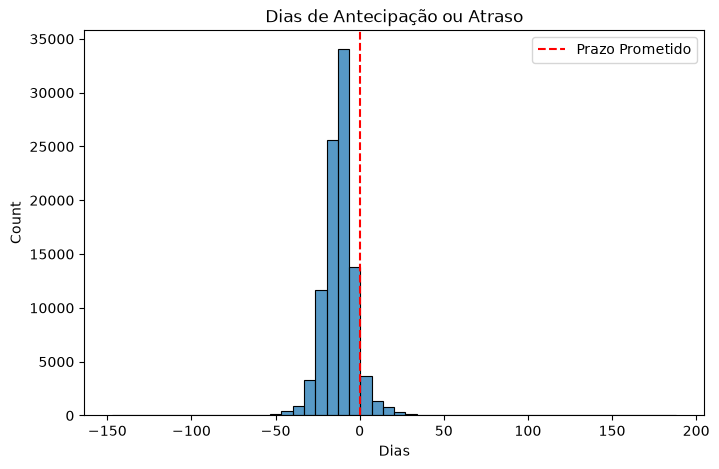

In [41]:
plt.figure(figsize=(8,5))

sns.histplot(
    orders["delivery_delay_days"],
    bins=50
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Prazo Prometido"
)

plt.legend()
plt.title("Dias de Antecipação ou Atraso")
plt.xlabel("Dias")

plt.show()